# 03 · The sim_v2 sandbox, walked through

**What this shows:** how one world is built, what is inside it, and *why* each scam happened, read straight from the records.
Code: `data/sim_v2/` (see its README for the commands). No comparison with real datasets here; that's a separate step.

Every section asks one question and ends with an **Inference**.

In [1]:
import sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT / 'backend'), str(ROOT / 'ml'), str(ROOT / 'data')]
pd.set_option('display.max_colwidth', 110); pd.set_option('display.width', 200); plt.rcParams['figure.figsize'] = (9, 3.4)
from sim_v2.core.config import load
from sim_v2.run import build
from sim_v2.export import write

OUT = ROOT / 'data/sim_v2_out/mid'
cfg = load(users=3000, days=30)                 # change size here; goal is 20,000 x 60
T = build(cfg); write(T, cfg, OUT)
led, ev, jr, dec, acc, users, rep, crews = (T[k] for k in ('ledger', 'context_events', 'journeys', 'decisions', 'accounts', 'users', 'reports', 'crews'))
pd.Series({k: len(v) for k, v in T.items()}, name='rows').to_frame().T

  population: 3,000 users, 12 localities, 36 crews (2.5s)


  everyday life + look-alikes (10.7s)
  scams: 136 journeys (10.9s)


  done in 20.8s


,handles,accounts,users,ledger,context_events,journeys,reports,decisions,crews
rows,8,51269,3000,195768,322295,136,3021,513,1069


## 1. What happens in this world?
Every payment has a `flow`; honest situations that look like scams carry a `scenario` tag (still flow `normal`).

In [2]:
U = set(users.upi_id)
t = led.assign(scenario=led.scenario.fillna('-'), by_user=led.from_upi.isin(U))
t.groupby(['flow', 'scenario']).agg(payments=('amount', 'size'), median_inr=('amount', 'median'),
      typed=('entry_method', lambda s: (s == 'typed').mean()), round_100=('amount', lambda a: ((a % 100 == 0) & (a >= 500)).mean())).round(2)

payments  median_inr  typed  round_100
flow          scenario                                                    
cashback      -                         2898         7.0   0.00       0.00
gig_payout    gig_credits              10927       177.0   1.00       0.00
mule_cover    -                         4870        92.0   0.00       0.00
mule_forward  -                         5679      9422.0   1.00       0.01
normal        -                       157925       177.0   0.14       0.07
              bill                      2020       785.0   0.50       0.01
              community_collection       991       500.0   0.32       0.41
              delivery_on_call          1219       797.0   0.00       0.15
              festival_gift             1584      5100.0   0.30       1.00
              it_support_anydesk         100      1461.5   0.61       0.05
              landlord_deposit            56     32400.0   1.00       0.88
              medical_emergency           57     16553.0   0.30       0.63
              rent                       919     12500.0   0.37       1.00
              second_hand_purchase        78      9450.0   1.00       0.88
scam          -                          187      8647.0   0.83       0.45
scam_bait     -                           48       265.5   1.00       0.00
scam_external -                         6210     10900.0   0.80       0.50

**Inference:**
- **Everyday life** is about 158k ordinary payments (median ₹177).
- **About 4,000 look-alike payments are mixed in:**
  - festival gifts (100% round);
  - rent (100% round);
  - landlord deposits and second-hand buys (typed by hand 100% of the time, median ₹9,450–32,400);
  - delivery payments made during an unknown call;
  - community funds with many payers.
- **Scam payments** (187, from 12 playbooks) are typed 83% of the time and round 45% of the time. "Round" is no longer a giveaway: look-alikes are round more often (58%).
- **Mules** (now about 2% of accounts) receive 6,210 payments from victims outside our users and forward most of it (5,679 forwards). Merchant-disguised mules also get 4,870 small "cover" QR payments.

## 2. One scam, start to finish
The same story `python -m sim_v2 trace <journey>` prints. Each payment's `cause_id` points to the decision that caused it.

In [3]:
jid = jr[(jr.playbook == 'task_job') & (jr.n_payments >= 3) & ~jr.is_demo].journey_id.iloc[0]
j = jr.set_index('journey_id').loc[jid]; print(jid, dict(j[['user_id', 'playbook', 'variant', 'outcome', 'n_payments', 'total_paid', 'reported']]))
d = dec[dec.journey_id == jid].assign(what=lambda x: x.kind + ' @ ' + x.step + ' -> ' + x.outcome.str.upper() + '  (p=' + x.p.round(2).astype(str) + ', draw=' + x.draw.round(2).astype(str) + ')')
p = led[(led.journey_id == jid)].assign(what=lambda x: x.flow + ' ₹' + x.amount.round().astype(int).astype(str) + ' ' + x.from_upi + ' -> ' + x.to_upi + ' [' + x.entry_method + ']')
e = ev[(ev.journey_id == jid) & (ev.event_type != 'pay_session')]
e = e.assign(what=[f'{a} {b}' for a, b in zip(e.event_type, e['attrs'])])
story = pd.concat([d.assign(kind='DECISION')[['ts', 'kind', 'what']], p.assign(kind='PAYMENT')[['ts', 'kind', 'what']], e.assign(kind='EVENT')[['ts', 'kind', 'what']]]).sort_values(['ts', 'kind'])
story.assign(ts=story.ts.dt.strftime('%m-%d %H:%M')).reset_index(drop=True)

j_000821 {'user_id': 'u_000821', 'playbook': 'task_job', 'variant': 'rewards', 'outcome': 'completed', 'n_payments': np.int64(5), 'total_paid': np.float64(68696.0), 'reported': np.True_}


,ts,kind,what
0,10-14 09:14,EVENT,"sms_lure {""conf"": 0.89, ""tag"": ""task_job""}"
1,10-14 09:16,DECISION,"victim @ hook -> COMPLY (p=0.67, draw=0.28)"
2,10-14 09:16,PAYMENT,scam_bait ₹245 usha.yadav33877@okaxis -> anil.mishra85756@okicici [typed]
3,10-14 14:37,PAYMENT,scam_bait ₹289 usha.yadav33877@okaxis -> anil.mishra85756@okicici [typed]
4,10-15 07:47,DECISION,"victim @ first_task -> COMPLY (p=0.71, draw=0.29)"
5,10-15 07:47,PAYMENT,scam ₹1567 anil.mishra85756@okicici -> 7014553787@ibl [qr]
6,10-15 09:21,PAYMENT,scam_bait ₹2073 usha.yadav33877@okaxis -> anil.mishra85756@okicici [typed]
7,10-15 10:20,PAYMENT,mule_forward ₹1264 7014553787@ibl -> usha.yadav33877@okaxis [typed]
8,10-15 14:16,DECISION,"victim @ escalate -> COMPLY (p=0.74, draw=0.55)"
9,10-15 14:16,PAYMENT,scam ₹4318 anil.mishra85756@okicici -> asha.jain65307@ybl [typed]


**Inference:** you can read *why* every row exists:
1. A task-job SMS arrives, and the victim replies (p = 0.67).
2. Two small "rewards" (₹245, ₹289) come from the crew's cash-out account.
3. The victim pays a ₹1,567 "task" and gets ₹2,073 back.
4. The asks climb: ₹4,318 → ₹8,122 → ₹18,389 → a ₹36,300 "withdrawal fee". Each one is a logged decision, and p drops from 0.76 to 0.61 as the asks grow.
5. Each payment goes to a different mule (the "level" accounts rotate). The mules forward the money to cash-out accounts, including the one that paid the rewards: a money loop the backend's ring signal (R11) looks for.
6. The victim reported it (draw 0.28 < p 0.50).

## 3. Why did victims pay or refuse?
Each victim decision is `p_comply = logistic(base + pressure + sunk cost − doubt − big ask)`. These are all the decisions in this world.

         decisions  mean_p  mean_big_ask_term  mean_sunk_term
outcome                                                      
comply         228    0.70              -0.61            0.03
delay           21    0.61              -2.26            0.02
refuse          71    0.56              -0.27            0.02


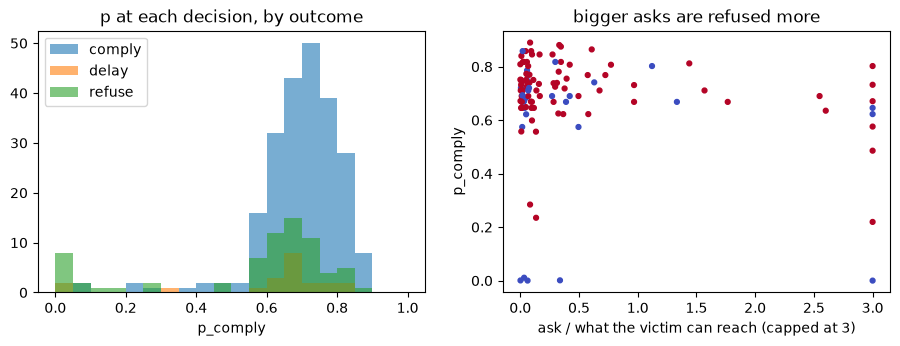

,journeys,paid_any,median_paid
playbook,,,
collect_request,4,0.75,2883.0
digital_arrest,29,0.38,0.0
electricity_disconnection,2,0.00,0.0
fake_customer_care,19,0.68,7816.0
fake_kyc_apk,13,0.62,16405.0
loan_fee,3,0.33,0.0
lottery_prize,6,0.17,0.0
marketplace_buyer,4,0.50,6700.0
refund_qr,12,0.50,1260.5


In [4]:
v = dec[dec.kind == 'victim'].copy()
inp = pd.json_normalize(v['inputs'].map(json.loads)); v = pd.concat([v.reset_index(drop=True), inp], axis=1)
v['ask_vs_capacity'] = v.ask_inr / v.capacity_inr
print(v.groupby('outcome').agg(decisions=('p', 'size'), mean_p=('p', 'mean'), mean_big_ask_term=('big_ask', 'mean'), mean_sunk_term=('sunk', 'mean')).round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for o, g in v.groupby('outcome'):
    ax[0].hist(g.p, bins=20, range=(0, 1), alpha=0.6, label=o)
ax[0].set_xlabel('p_comply'); ax[0].legend(); ax[0].set_title('p at each decision, by outcome')
asks = v[v.ask_inr > 0]
ax[1].scatter(asks.ask_vs_capacity.clip(upper=3), asks.p, c=(asks.outcome == 'comply'), cmap='coolwarm', s=12)
ax[1].set_xlabel('ask / what the victim can reach (capped at 3)'); ax[1].set_ylabel('p_comply'); ax[1].set_title('bigger asks are refused more'); plt.show()
jr.groupby('playbook').agg(journeys=('journey_id', 'size'), paid_any=('n_payments', lambda s: (s > 0).mean()), median_paid=('total_paid', 'median')).round(2)

**Inference:**
- **Asks:** victims complied with 228 asks, refused 71 and delayed 21.
- **Delays happen at large asks:** their mean big-ask term is −2.26, much bigger than the −0.61 when complying.
- **Refusals happen mostly at the first contact,** where there is no ask, so their big-ask term is small (−0.27). People who hang up early never pay.
- **By scam type**, among approached victims who paid anything:
  - collect request 75%;
  - fake customer care 68%;
  - trading 64%;
  - fake KYC 62%;
  - lottery only 17%, because few people believe the prize message.
- **All of these rates come from guessed weights** (`assumptions.yaml` → `victim`). They're the first thing to tune against real cases (`config/cases.csv`).

## 4. Why scams are hard to spot: look-alikes share their signals
For payments by our users: how often each group is typed, round, to a never-paid payee, or made **while on a call with an unknown number**.

In [5]:
en = ev[ev.event_type == 'call_ended'].copy()            # each ended call: its span and whether the number was unknown
a = en['attrs'].map(json.loads)
en['start'] = en.ts - pd.to_timedelta(a.map(lambda x: x['duration_min']), unit='m')
unk = en[a.map(lambda x: not x['in_contacts']).to_numpy()][['user_id', 'start', 'ts']].rename(columns={'ts': 'end'})
up = led[led.from_upi.isin(U)].copy()
up['user_id'] = up.from_upi.map(users.set_index('upi_id').user_id)
up['group'] = np.where(up.flow == 'scam', 'SCAM', np.where(up.scenario.notna() & ~up.scenario.isin(['rent', 'bill']), 'look-alike', 'everyday'))
m = up[['user_id', 'ts']].reset_index().merge(unk, on='user_id')
up['on_unknown_call'] = up.index.isin(set(m[(m.ts >= m.start) & (m.ts <= m.end)]['index']))
up['new_payee'] = ~up.sort_values('ts').duplicated(['from_upi', 'to_upi'])
up.groupby('group').agg(payments=('amount', 'size'), median_inr=('amount', 'median'), typed=('entry_method', lambda s: (s == 'typed').mean()),
                        round_100=('amount', lambda a: ((a % 100 == 0) & (a >= 500)).mean()), new_payee=('new_payee', 'mean'),
                        on_unknown_call=('on_unknown_call', 'mean')).round(3)

,payments,median_inr,typed,round_100,new_payee,on_unknown_call
group,,,,,,
SCAM,187,8647.0,0.834,0.455,0.663,0.406
everyday,160864,181.0,0.142,0.074,0.226,0.001
look-alike,4037,1600.0,0.237,0.578,0.698,0.083


**Inference:** **this table is why the problem is hard (and not faked).** No single clue separates scams:

| Clue | Scams | Look-alikes |
|---|---|---|
| Typed by hand | 83% | 24% |
| Round amount | 45% | 58% (more than scams) |
| New payee | 66% | 70% (more than scams) |
| During an unknown call | 41% | 8% |

- **Typed by hand:** the strongest single tell.
- **Round amount and new payee:** look-alikes score *higher* than scams, so neither is a giveaway.
- **During an unknown call:** strong, but honest people do it too (delivery agents, sellers, landlords).

Combining families is what RUKO's two-family rule is for.

**Still to improve:** "typed" is still a strong tell. More playbooks could use QR codes or saved contacts.

## 5. Mules: short-lived, mixed ages, mostly unknown to the lists
A crew keeps a few mule slots. Each mule works a few days and is replaced.

In [6]:
crews['days_active'] = (crews.active_to - crews.active_from).dt.total_seconds() / 86400
a = acc.set_index('upi_id')
crews['age_at_start_days'] = (crews.active_from - crews.mule_upi_id.map(a.created_at)).dt.days
listed = rep[~rep.is_false & (rep.identifier_type == 'upi_id')].groupby('identifier').listed_at.min()
scam = led[led.flow == 'scam']
print(f"scam payments to a payee already listed at that moment: {(scam.to_upi.map(listed) < scam.ts).mean():.0%}")
crews.groupby('mule_kind').agg(mules=('mule_upi_id', 'size'), days_active=('days_active', 'median'), age_at_start_days=('age_at_start_days', 'median')).round(1)

scam payments to a payee already listed at that moment: 16%


,mules,days_active,age_at_start_days
mule_kind,,,
merchant_disguised,220,7.0,430.0
plain,364,6.0,31.0
rented,314,6.0,1349.5
slow_forward,85,6.0,65.0
warm_up,86,6.0,30.0


**Inference:**
- **Mules are short-lived:** each works a median of 6–7 days before being replaced.
- **Their ages vary widely:**
  - plain and warm-up mules are about 1 month old;
  - merchant-disguised ones about 14 months;
  - rented ones about 3.7 years.

  So account age can't give the label away.
- **Most scam money goes to mules no list knows yet:** only **16%** of scam payments reach a payee already listed at that moment (the old simulator was 94%).

## 6. Same scenario, different seeds = controlled variation
Three small worlds (500 users × 14 days) with seeds 7, 8, 9: the numbers move, but stay inside the configured ranges.

In [7]:
rows = {}
for s in (7, 8, 9):
    t = build(load(users=500, days=14, seed=s), log=lambda *_: None)
    L, J = t['ledger'], t['journeys']
    rows[f'seed {s}'] = {'payments': len(L), 'journeys': len(J), 'journeys that paid': int((J.n_payments > 0).sum()),
                         'scam ₹ total': int(J.total_paid.sum()), 'look-alike payments': int(L.scenario.notna().sum()),
                         'median everyday ₹': float(L[(L.flow == 'normal') & L.scenario.isna()].amount.median())}
pd.DataFrame(rows)

,seed 7,seed 8,seed 9
payments,15946.0,18368.0,17194.0
journeys,18.0,9.0,9.0
journeys that paid,10.0,5.0,7.0
scam ₹ total,685870.0,489277.0,919635.0
look-alike payments,1416.0,1313.0,1492.0
median everyday ₹,170.0,192.0,174.0


**Inference:** the same configuration with seeds 7, 8 and 9 gives different worlds:
- 15,946–18,368 payments;
- 9–18 journeys (3 of them always the scripted demo);
- ₹4.9–9.2 lakh lost to scams.

Typical behaviour stays inside the configured ranges (median everyday payment ₹170–192). That's controlled randomness: the same scenario, different records, and seed 7 always rebuilds exactly the same world.